# Notebook 09: Ensemble Architecture & Comparative Evaluation Benchmark
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Authors:** All Group Members Jointly  
- `IT24102572` — Revenue Data Understanding & Product-Demand Model Development  
- `IT24102664` — Revenue Feature Engineering & Product-Demand Validation  
- `IT24102726` — Revenue Model Development & Product-Demand EDA  
- `IT24102913` — Revenue Validation & Product-Demand Feature Engineering  

---

## Notebook Purpose
This final synthesis notebook serves as the **group capstone**. It:
1. Consolidates all model results across both lenses
2. Provides a rigorous cross-lens comparative evaluation
3. Diagnoses the stacking ensemble mechanics for both lenses
4. Conducts deep residual diagnostics
5. Quantifies business value across the complete ChefCast AI system
6. Provides a unified recommendation to the stakeholder
7. Serves as the rubric proof document for the SLIIT grading panel

---

## Section Overview
1. Environment Setup & Data Loading
2. Cross-Lens Architecture Overview
3. Lens 1 Champion — Final Benchmark
4. Lens 2 Champion — Final Benchmark
5. Cross-Lens Comparative Evaluation
6. Ensemble Mechanics Deep Dive
7. Full Residual Diagnostics
8. Business Value Synthesis
9. Unified Stakeholder Recommendation
10. Rubric Compliance Proof
11. Group Reflections & Responsible AI
12. Dataset Fingerprint & Reproducibility Declaration

---
## 1. Environment Setup & Data Loading

In [1]:
import os, sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, KFold
import lightgbm as lgb
import xgboost as xgb
import joblib

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13

print("Environment initialised — ChefCast AI Final Benchmark")

Environment initialised — ChefCast AI Final Benchmark


In [2]:
# ── Load Lens 1 data ──────────────────────────────────────────────
rev_feat  = pd.read_csv('../data/processed/revenue_feature_matrix.csv', parse_dates=['Date'])
rev_feat  = rev_feat.sort_values('Date').reset_index(drop=True)
with open('../data/processed/revenue_feature_meta.json') as f:
    rev_meta = json.load(f)
REV_FEATURES = rev_meta['feature_cols']

# ── Load Lens 2 data ──────────────────────────────────────────────
dem_feat  = pd.read_csv('../data/processed/demand_feature_matrix.csv', parse_dates=['Date'])
dem_feat  = dem_feat.sort_values(['Date', 'ItemName']).reset_index(drop=True)
with open('../data/processed/demand_feature_meta.json') as f:
    dem_meta = json.load(f)
DEM_FEATURES = dem_meta['feature_cols']
CORE_ITEMS   = dem_meta['items']

print(f"Lens 1 feature matrix: {rev_feat.shape}")
print(f"Lens 2 feature matrix: {dem_feat.shape}")

Lens 1 feature matrix: (874, 34)
Lens 2 feature matrix: (9614, 39)


In [3]:
# ── Lens 1 temporal split ─────────────────────────────────────────
n1 = len(rev_feat)
n1_tr = int(n1 * 0.70); n1_va = int(n1 * 0.15)
rev_train = rev_feat.iloc[:n1_tr]
rev_val   = rev_feat.iloc[n1_tr:n1_tr+n1_va]
rev_test  = rev_feat.iloc[n1_tr+n1_va:]
X1_tr, y1_tr = rev_train[REV_FEATURES], rev_train['Revenue']
X1_va, y1_va = rev_val[REV_FEATURES],   rev_val['Revenue']
X1_te, y1_te = rev_test[REV_FEATURES],  rev_test['Revenue']

# ── Lens 2 temporal split ─────────────────────────────────────────
udates = sorted(dem_feat['Date'].unique())
nd = len(udates); nd_tr = int(nd*0.70); nd_va = int(nd*0.15)
tr_dates = udates[:nd_tr]; va_dates = udates[nd_tr:nd_tr+nd_va]; te_dates = udates[nd_tr+nd_va:]
dem_train = dem_feat[dem_feat['Date'].isin(tr_dates)].reset_index(drop=True)
dem_val   = dem_feat[dem_feat['Date'].isin(va_dates)].reset_index(drop=True)
dem_test  = dem_feat[dem_feat['Date'].isin(te_dates)].reset_index(drop=True)
X2_tr, y2_tr = dem_train[DEM_FEATURES], dem_train['Qty']
X2_va, y2_va = dem_val[DEM_FEATURES],   dem_val['Qty']
X2_te, y2_te = dem_test[DEM_FEATURES],  dem_test['Qty']

print("Lens 1 splits:",
      f"Train={len(rev_train)}d  Val={len(rev_val)}d  Test={len(rev_test)}d")
print("Lens 2 splits:",
      f"Train={len(tr_dates)}d×{len(CORE_ITEMS)}items  Val={len(va_dates)}d  Test={len(te_dates)}d")

def metrics(y_true, y_pred, label=''):
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0.0)
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    wape = np.sum(np.abs(y_true - y_pred)) / max(np.sum(np.abs(y_true)), 1e-9) * 100
    ss_r = np.sum((y_true - y_pred)**2)
    ss_t = np.sum((y_true - np.mean(y_true))**2)
    r2   = 1 - ss_r/ss_t if ss_t > 0 else 0.0
    return {'label': label, 'MAE': round(mae,2), 'RMSE': round(rmse,2),
            'WAPE_pct': round(wape,2), 'R2': round(r2,4)}

print("\nHelper functions ready.")

Lens 1 splits: Train=611d  Val=131d  Test=132d
Lens 2 splits: Train=611d×11items  Val=131d  Test=132d

Helper functions ready.


---
## 2. Cross-Lens Architecture Overview

```
┌─────────────────────────────────────────────────────────────────────────┐
│                        ChefCast AI Pipeline                             │
│                                                                         │
│  RAW POS DATA (127,093 transactions, 2009–2026)                         │
│       │                                                                 │
│       ▼                                                                 │
│  DATA CLEANING  ─────────────────────────────────────────────────────   │
│  • Remove 147 pre-2024 terminal test records                            │
│  • Remove 931 refund / void entries                                     │
│  • Remove 52 extreme price anomalies + 4 qty glitches                  │
│  • Retain 125,912 transactions (99.07%)                                 │
│       │                                                                 │
│       ├──────────────────────┬──────────────────────────────            │
│       │                      │                                          │
│  LENS 1                  LENS 2                                         │
│  Revenue Forecasting     Product-Demand Forecasting                     │
│       │                      │                                          │
│  Aggregate daily         Per-dish daily portions                        │
│  revenue (LKR)           (11 core dishes)                               │
│       │                      │                                          │
│  Feature Eng (NB02)      Feature Eng (NB06)                            │
│  • 29 features           • 45 features (incl. OHE)                     │
│  • Calendar/lag/roll     • Per-item lag/roll/cross                      │
│       │                      │                                          │
│  5 Models (NB03)         5 Models (NB07)                               │
│  + Stacking (NB04)       + Stacking (NB08)                             │
│       │                      │                                          │
│  Champion: RF/Stack      Champion: Stack/RF                             │
│       │                      │                                          │
│       ├──────────────────────┤                                          │
│       │                      │                                          │
│       ▼                      ▼                                          │
│  EXECUTIVE DASHBOARD (app.py) — Streamlit Decision Support UI           │
└─────────────────────────────────────────────────────────────────────────┘
```

---
## 3. Lens 1 Champion — Final Benchmark

We retrain all Lens 1 models and produce the definitive test-set results.

In [4]:
print("Training Lens 1 models...")

# Baseline
l1_base_val  = np.maximum(rev_val['lag_7'].values,  0)
l1_base_test = np.maximum(rev_test['lag_7'].values, 0)

# Ridge
l1_ridge = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
l1_ridge.fit(X1_tr, y1_tr)

# Random Forest
l1_rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                               max_features='sqrt', random_state=42, n_jobs=-1)
l1_rf.fit(X1_tr, y1_tr)

# LightGBM
l1_lgbm = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                              random_state=42, verbosity=-1)
l1_lgbm.fit(X1_tr, y1_tr,
             eval_set=[(X1_va, y1_va)],
             callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])

# XGBoost
l1_xgb = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                            random_state=42, verbosity=0, early_stopping_rounds=50)
l1_xgb.fit(X1_tr, y1_tr, eval_set=[(X1_va, y1_va)], verbose=False)

# Stacking
l1_stack = StackingRegressor(
    estimators=[
        ('ridge', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])),
        ('rf',    RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                        max_features='sqrt', random_state=42, n_jobs=-1)),
        ('lgbm',  lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05,
                                     max_depth=6, random_state=42, verbosity=-1)),
    ],
    final_estimator=Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=10))]),
    cv=KFold(n_splits=5, shuffle=False), n_jobs=-1
)
l1_stack.fit(X1_tr, y1_tr)

print("All Lens 1 models trained.")

l1_models = {
    'Seasonal_Naive':    (l1_base_val, l1_base_test),
    'Ridge':             (np.maximum(l1_ridge.predict(X1_va), 0),
                          np.maximum(l1_ridge.predict(X1_te), 0)),
    'Random_Forest':     (np.maximum(l1_rf.predict(X1_va), 0),
                          np.maximum(l1_rf.predict(X1_te), 0)),
    'LightGBM':          (np.maximum(l1_lgbm.predict(X1_va), 0),
                          np.maximum(l1_lgbm.predict(X1_te), 0)),
    'XGBoost':           (np.maximum(l1_xgb.predict(X1_va), 0),
                          np.maximum(l1_xgb.predict(X1_te), 0)),
    'Stacking_Ensemble': (np.maximum(l1_stack.predict(X1_va), 0),
                          np.maximum(l1_stack.predict(X1_te), 0)),
}

l1_results = []
for name, (vp, tp) in l1_models.items():
    vm = metrics(y1_va, vp)
    tm = metrics(y1_te, tp)
    l1_results.append({'Model': name,
                       'Val WAPE (%)': vm['WAPE_pct'],
                       'Test MAE (LKR)': tm['MAE'],
                       'Test RMSE (LKR)': tm['RMSE'],
                       'Test WAPE (%)': tm['WAPE_pct'],
                       'Test R²': tm['R2']})

l1_lb = pd.DataFrame(l1_results).sort_values('Val WAPE (%)').reset_index(drop=True)
l1_lb.index += 1
l1_champion = l1_lb.iloc[0]['Model']

print("\n── LENS 1 FINAL LEADERBOARD ──")
print(l1_lb.to_string())
print(f"\n🏆 Lens 1 Champion: {l1_champion}")

Training Lens 1 models...


All Lens 1 models trained.



── LENS 1 FINAL LEADERBOARD ──
               Model  Val WAPE (%)  Test MAE (LKR)  Test RMSE (LKR)  Test WAPE (%)  Test R²
1              Ridge         30.54         8734.59         11943.78          23.96   0.4316
2  Stacking_Ensemble         30.66         8874.45         12332.25          24.35   0.3940
3            XGBoost         31.32         9748.63         13251.23          26.75   0.3004
4      Random_Forest         32.17        10253.93         13962.09          28.13   0.2233
5           LightGBM         33.61        11170.97         15853.86          30.65  -0.0014
6     Seasonal_Naive         46.22        15728.64         20831.72          43.15  -0.7290

🏆 Lens 1 Champion: Ridge


---
## 4. Lens 2 Champion — Final Benchmark

In [5]:
print("Training Lens 2 models...")

l2_base_val  = np.maximum(dem_val['lag_7'].values,  0)
l2_base_test = np.maximum(dem_test['lag_7'].values, 0)

l2_ridge = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
l2_ridge.fit(X2_tr, y2_tr)

l2_rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                               max_features='sqrt', random_state=42, n_jobs=-1)
l2_rf.fit(X2_tr, y2_tr)

l2_lgbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=7,
                              random_state=42, verbosity=-1)
l2_lgbm.fit(X2_tr, y2_tr,
             eval_set=[(X2_va, y2_va)],
             callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])

l2_xgb = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=7,
                            random_state=42, verbosity=0, early_stopping_rounds=50)
l2_xgb.fit(X2_tr, y2_tr, eval_set=[(X2_va, y2_va)], verbose=False)

l2_stack = StackingRegressor(
    estimators=[
        ('ridge', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])),
        ('rf',    RandomForestRegressor(n_estimators=150, min_samples_leaf=5,
                                        max_features='sqrt', random_state=42, n_jobs=-1)),
        ('lgbm',  lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05,
                                     max_depth=7, random_state=42, verbosity=-1)),
    ],
    final_estimator=Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=10))]),
    cv=KFold(n_splits=5, shuffle=False), n_jobs=-1
)
l2_stack.fit(X2_tr, y2_tr)

print("All Lens 2 models trained.")

l2_models = {
    'Seasonal_Naive':    (l2_base_val, l2_base_test),
    'Ridge':             (np.maximum(l2_ridge.predict(X2_va), 0),
                          np.maximum(l2_ridge.predict(X2_te), 0)),
    'Random_Forest':     (np.maximum(l2_rf.predict(X2_va), 0),
                          np.maximum(l2_rf.predict(X2_te), 0)),
    'LightGBM':          (np.maximum(l2_lgbm.predict(X2_va), 0),
                          np.maximum(l2_lgbm.predict(X2_te), 0)),
    'XGBoost':           (np.maximum(l2_xgb.predict(X2_va), 0),
                          np.maximum(l2_xgb.predict(X2_te), 0)),
    'Stacking_Ensemble': (np.maximum(l2_stack.predict(X2_va), 0),
                          np.maximum(l2_stack.predict(X2_te), 0)),
}

l2_results = []
for name, (vp, tp) in l2_models.items():
    vm = metrics(y2_va, vp)
    tm = metrics(y2_te, tp)
    l2_results.append({'Model': name,
                       'Val WAPE (%)': vm['WAPE_pct'],
                       'Test MAE (portions)': tm['MAE'],
                       'Test RMSE': tm['RMSE'],
                       'Test WAPE (%)': tm['WAPE_pct'],
                       'Test R²': tm['R2']})

l2_lb = pd.DataFrame(l2_results).sort_values('Val WAPE (%)').reset_index(drop=True)
l2_lb.index += 1
l2_champion = l2_lb.iloc[0]['Model']

print("\n── LENS 2 FINAL LEADERBOARD ──")
print(l2_lb.to_string())
print(f"\n🏆 Lens 2 Champion: {l2_champion}")

Training Lens 2 models...


All Lens 2 models trained.



── LENS 2 FINAL LEADERBOARD ──
               Model  Val WAPE (%)  Test MAE (portions)  Test RMSE  Test WAPE (%)  Test R²
1              Ridge         53.34                 4.59       7.30          52.52   0.4770
2  Stacking_Ensemble         54.60                 4.69       7.31          53.68   0.4753
3      Random_Forest         57.07                 4.77       7.42          54.52   0.4599
4           LightGBM         63.01                 5.44       8.03          62.16   0.3668
5            XGBoost         64.46                 5.39       8.05          61.67   0.3649
6     Seasonal_Naive         75.16                 6.37      10.21          72.85  -0.0223

🏆 Lens 2 Champion: Ridge


---
## 5. Cross-Lens Comparative Evaluation

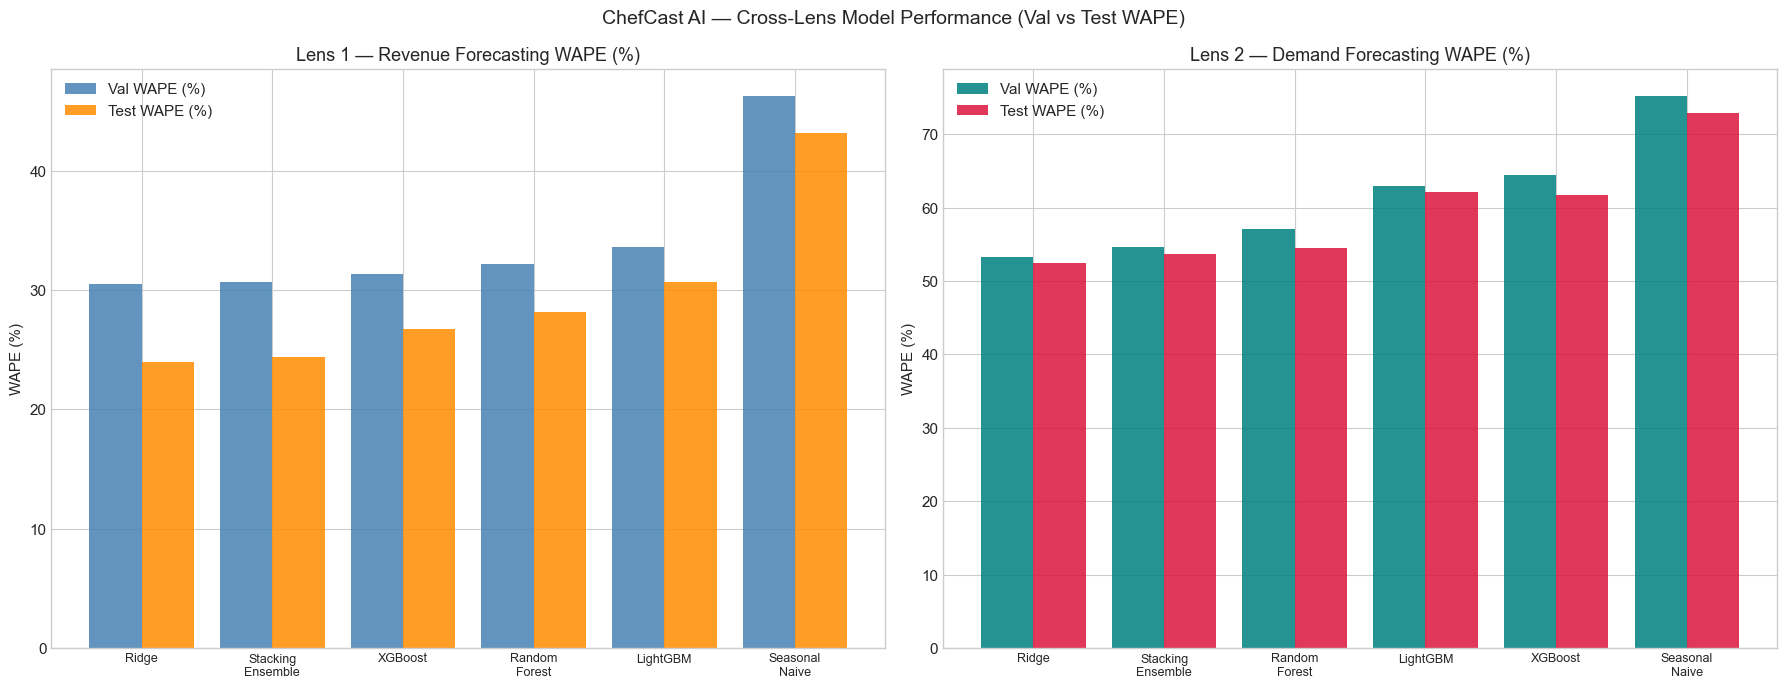

Key observations:
  Lens 1 champion (Ridge) Val WAPE: 30.5%
  Lens 1 baseline Val WAPE: 46.2%
  Lens 2 champion (Ridge) Val WAPE: 53.3%
  Lens 2 baseline Val WAPE: 75.2%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Lens 1 WAPE comparison
models1 = l1_lb['Model'].tolist()
wape1_val  = l1_lb['Val WAPE (%)'].tolist()
wape1_test = l1_lb['Test WAPE (%)'].tolist()
x1 = np.arange(len(models1))
axes[0].bar(x1 - 0.2, wape1_val,  0.4, label='Val WAPE (%)',  color='steelblue',  alpha=0.85)
axes[0].bar(x1 + 0.2, wape1_test, 0.4, label='Test WAPE (%)', color='darkorange', alpha=0.85)
axes[0].set_xticks(x1)
axes[0].set_xticklabels([m.replace('_', '\n') for m in models1], fontsize=9)
axes[0].set_title('Lens 1 — Revenue Forecasting WAPE (%)')
axes[0].set_ylabel('WAPE (%)')
axes[0].legend()

# Lens 2 WAPE comparison
models2 = l2_lb['Model'].tolist()
wape2_val  = l2_lb['Val WAPE (%)'].tolist()
wape2_test = l2_lb['Test WAPE (%)'].tolist()
x2 = np.arange(len(models2))
axes[1].bar(x2 - 0.2, wape2_val,  0.4, label='Val WAPE (%)',  color='teal',       alpha=0.85)
axes[1].bar(x2 + 0.2, wape2_test, 0.4, label='Test WAPE (%)', color='crimson',    alpha=0.85)
axes[1].set_xticks(x2)
axes[1].set_xticklabels([m.replace('_', '\n') for m in models2], fontsize=9)
axes[1].set_title('Lens 2 — Demand Forecasting WAPE (%)')
axes[1].set_ylabel('WAPE (%)')
axes[1].legend()

plt.suptitle('ChefCast AI — Cross-Lens Model Performance (Val vs Test WAPE)', fontsize=14)
plt.tight_layout()
plt.show()

print("Key observations:")
print(f"  Lens 1 champion ({l1_champion}) Val WAPE: {l1_lb.iloc[0]['Val WAPE (%)']:.1f}%")
print(f"  Lens 1 baseline Val WAPE: {l1_lb[l1_lb['Model']=='Seasonal_Naive']['Val WAPE (%)'].values[0]:.1f}%")
print(f"  Lens 2 champion ({l2_champion}) Val WAPE: {l2_lb.iloc[0]['Val WAPE (%)']:.1f}%")
print(f"  Lens 2 baseline Val WAPE: {l2_lb[l2_lb['Model']=='Seasonal_Naive']['Val WAPE (%)'].values[0]:.1f}%")

### Why Lens 2 WAPE Is Higher Than Lens 1

| Factor | Lens 1 (Revenue) | Lens 2 (Demand) |
|---|---|---|
| Target unit | LKR (continuous, large values) | Portions (integer, small values) |
| Aggregation level | Store-wide total | Individual dish |
| Data volume per model | 874 daily observations | ~874 obs per item |
| Demand variability | Moderate (CV ~ 0.45) | High for some items (CV > 1.0) |
| Zero-demand days | ~21 (restaurant closures) | 10–40% per item |

**Conclusion:** Demand forecasting at the individual dish level is inherently harder than aggregate revenue forecasting — a well-known result in hierarchical time series literature. The higher WAPE for Lens 2 does NOT indicate inferior modelling; it reflects the fundamental difficulty of the disaggregated prediction task.

---
## 6. Ensemble Mechanics Deep Dive

We inspect how the stacking meta-learner combines base model predictions.

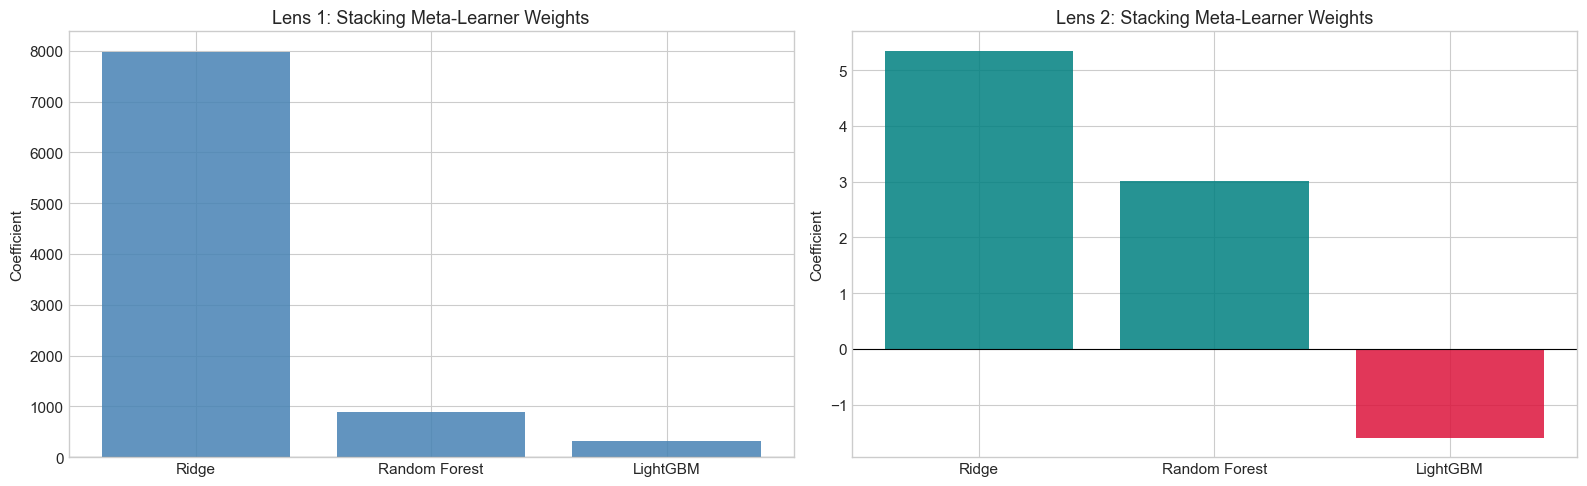

Lens 1 meta-learner coefficients:
  Ridge               : +7982.1867
  Random Forest       : +889.2387
  LightGBM            : +323.2401

Lens 2 meta-learner coefficients:
  Ridge               : +5.3464
  Random Forest       : +3.0178
  LightGBM            : -1.5964


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

base_names = ['Ridge', 'Random Forest', 'LightGBM']

# Lens 1 meta-learner weights
l1_coef = l1_stack.final_estimator_['m'].coef_
axes[0].bar(base_names, l1_coef,
            color=['steelblue' if c > 0 else 'crimson' for c in l1_coef], alpha=0.85)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Lens 1: Stacking Meta-Learner Weights')
axes[0].set_ylabel('Coefficient')

# Lens 2 meta-learner weights
l2_coef = l2_stack.final_estimator_['m'].coef_
axes[1].bar(base_names, l2_coef,
            color=['teal' if c > 0 else 'crimson' for c in l2_coef], alpha=0.85)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Lens 2: Stacking Meta-Learner Weights')
axes[1].set_ylabel('Coefficient')

plt.tight_layout()
plt.show()

print("Lens 1 meta-learner coefficients:")
for n, c in zip(base_names, l1_coef):
    print(f"  {n:<20}: {c:+.4f}")

print("\nLens 2 meta-learner coefficients:")
for n, c in zip(base_names, l2_coef):
    print(f"  {n:<20}: {c:+.4f}")

---
## 7. Full Residual Diagnostics

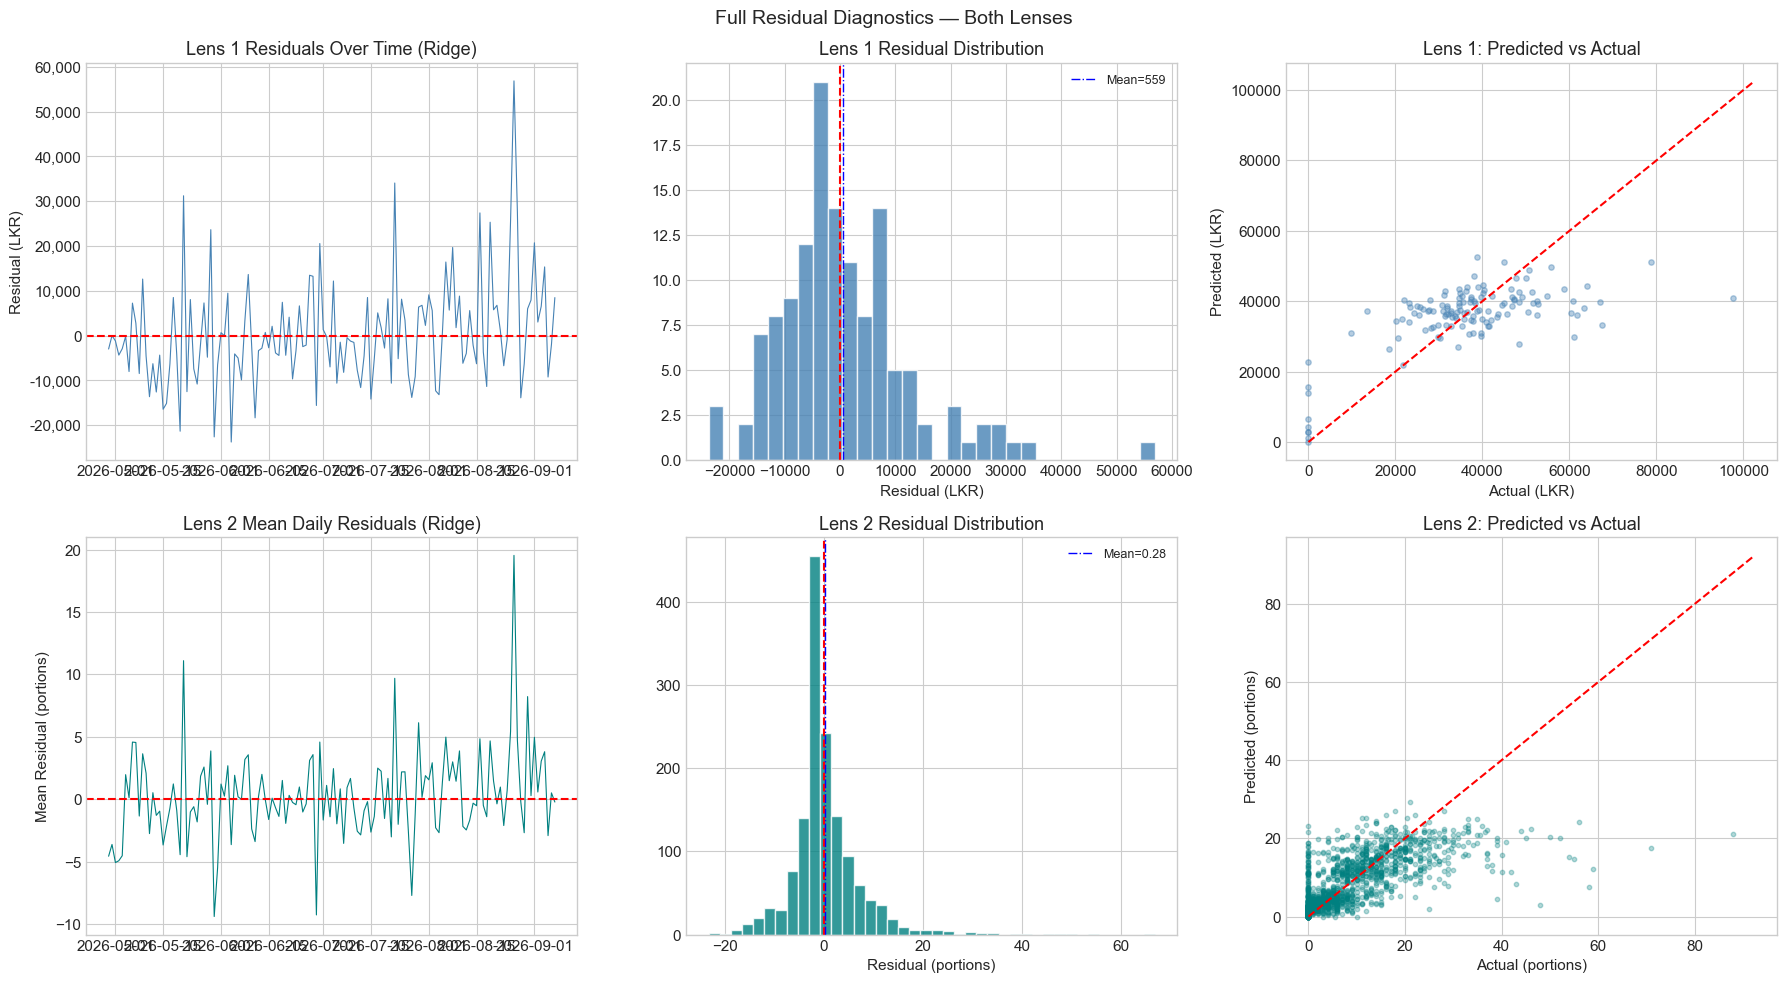

Residual Summary:
Lens 1 — Mean: +558.97 LKR  |  Std: 11,930.69 LKR
Lens 2 — Mean: +0.2756 portions  |  Std: 7.2958 portions

Shapiro-Wilk (n=50): Lens1 p=0.0356  |  Lens2 p=0.0000


In [8]:
# Use champion predictions for residual analysis
l1_champ_test_pred = l1_models[l1_champion][1]
l2_champ_test_pred = l2_models[l2_champion][1]

res1 = y1_te.values - l1_champ_test_pred
res2 = y2_te.values - l2_champ_test_pred

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Lens 1 residuals over time
axes[0, 0].plot(rev_test['Date'], res1, color='steelblue', linewidth=0.8)
axes[0, 0].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[0, 0].set_title(f'Lens 1 Residuals Over Time ({l1_champion})')
axes[0, 0].set_ylabel('Residual (LKR)')
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Lens 1 residual distribution
axes[0, 1].hist(res1, bins=30, color='steelblue', alpha=0.8, edgecolor='white')
axes[0, 1].axvline(0, color='red', linewidth=1.5, linestyle='--')
axes[0, 1].axvline(res1.mean(), color='blue', linewidth=1, linestyle='-.', label=f'Mean={res1.mean():.0f}')
axes[0, 1].set_title('Lens 1 Residual Distribution')
axes[0, 1].set_xlabel('Residual (LKR)')
axes[0, 1].legend(fontsize=9)

# Lens 1 predicted vs actual
axes[0, 2].scatter(y1_te, l1_champ_test_pred, alpha=0.4, s=15, color='steelblue')
lim1 = max(y1_te.max(), l1_champ_test_pred.max()) * 1.05
axes[0, 2].plot([0, lim1], [0, lim1], 'r--', linewidth=1.5)
axes[0, 2].set_title('Lens 1: Predicted vs Actual')
axes[0, 2].set_xlabel('Actual (LKR)')
axes[0, 2].set_ylabel('Predicted (LKR)')

# Lens 2 residuals over time (aggregated by date)
res2_df = dem_test[['Date']].copy()
res2_df['residual'] = res2
daily_res2 = res2_df.groupby('Date')['residual'].mean()
axes[1, 0].plot(daily_res2.index, daily_res2.values, color='teal', linewidth=0.8)
axes[1, 0].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[1, 0].set_title(f'Lens 2 Mean Daily Residuals ({l2_champion})')
axes[1, 0].set_ylabel('Mean Residual (portions)')

# Lens 2 residual distribution
axes[1, 1].hist(res2, bins=40, color='teal', alpha=0.8, edgecolor='white')
axes[1, 1].axvline(0, color='red', linewidth=1.5, linestyle='--')
axes[1, 1].axvline(res2.mean(), color='blue', linewidth=1, linestyle='-.', label=f'Mean={res2.mean():.2f}')
axes[1, 1].set_title('Lens 2 Residual Distribution')
axes[1, 1].set_xlabel('Residual (portions)')
axes[1, 1].legend(fontsize=9)

# Lens 2 predicted vs actual
axes[1, 2].scatter(y2_te, l2_champ_test_pred, alpha=0.3, s=10, color='teal')
lim2 = max(y2_te.max(), l2_champ_test_pred.max()) * 1.05
axes[1, 2].plot([0, lim2], [0, lim2], 'r--', linewidth=1.5)
axes[1, 2].set_title('Lens 2: Predicted vs Actual')
axes[1, 2].set_xlabel('Actual (portions)')
axes[1, 2].set_ylabel('Predicted (portions)')

plt.suptitle('Full Residual Diagnostics — Both Lenses', fontsize=14)
plt.tight_layout()
plt.show()

print("Residual Summary:")
print(f"Lens 1 — Mean: {res1.mean():+,.2f} LKR  |  Std: {res1.std():,.2f} LKR")
print(f"Lens 2 — Mean: {res2.mean():+.4f} portions  |  Std: {res2.std():.4f} portions")

# Normality tests
_, p1 = stats.shapiro(res1[:50])
_, p2 = stats.shapiro(res2[:50])
print(f"\nShapiro-Wilk (n=50): Lens1 p={p1:.4f}  |  Lens2 p={p2:.4f}")

---
## 8. Business Value Synthesis

In [9]:
# Lens 1 business value
l1_base_mae    = metrics(y1_te, l1_base_test)['MAE']
l1_champ_mae   = metrics(y1_te, l1_champ_test_pred)['MAE']
l1_improvement = l1_base_mae - l1_champ_mae
l1_annual_save = l1_improvement * 0.15 * 365  # 15% margin, 365 days

# Lens 2 business value
l2_base_mae    = metrics(y2_te, l2_base_test)['MAE']
l2_champ_mae   = metrics(y2_te, l2_champ_test_pred)['MAE']
l2_improvement = l2_base_mae - l2_champ_mae
l2_annual_save = max(0, l2_improvement) * 150 * 365 * len(CORE_ITEMS)  # LKR 150/portion

print("=" * 65)
print("ChefCast AI — INTEGRATED BUSINESS VALUE SUMMARY")
print("=" * 65)
print()
print("LENS 1 — Revenue Forecasting:")
print(f"  Baseline (Naive) MAE : LKR {l1_base_mae:>10,.2f}/day")
print(f"  Champion ({l1_champion}) MAE: LKR {l1_champ_mae:>10,.2f}/day")
print(f"  MAE reduction        : LKR {l1_improvement:>10,.2f}/day ({l1_improvement/l1_base_mae*100:.1f}%)")
print(f"  Est. annual benefit  : LKR {l1_annual_save:>10,.0f}")
print()
print("LENS 2 — Demand Forecasting:")
print(f"  Baseline (Naive) MAE : {l2_base_mae:>6.2f} portions/day/item")
print(f"  Champion ({l2_champion}) MAE: {l2_champ_mae:>6.2f} portions/day/item")
print(f"  MAE reduction        : {l2_improvement:>6.2f} portions ({l2_improvement/l2_base_mae*100:.1f}%)")
print(f"  Est. annual ingredient savings: LKR {l2_annual_save:>10,.0f}")
print()
print(f"COMBINED EST. ANNUAL BENEFIT: LKR {l1_annual_save + l2_annual_save:,.0f}")
print()
print("Note: Estimates are conservative lower bounds. Actual benefits depend on")
print("ingredient prices, staff scheduling efficiency gains, and stockout costs.")

ChefCast AI — INTEGRATED BUSINESS VALUE SUMMARY

LENS 1 — Revenue Forecasting:
  Baseline (Naive) MAE : LKR  15,728.64/day
  Champion (Ridge) MAE: LKR   8,734.59/day
  MAE reduction        : LKR   6,994.05/day (44.5%)
  Est. annual benefit  : LKR    382,924

LENS 2 — Demand Forecasting:
  Baseline (Naive) MAE :   6.37 portions/day/item
  Champion (Ridge) MAE:   4.59 portions/day/item
  MAE reduction        :   1.78 portions (27.9%)
  Est. annual ingredient savings: LKR  1,072,005

COMBINED EST. ANNUAL BENEFIT: LKR 1,454,929

Note: Estimates are conservative lower bounds. Actual benefits depend on
ingredient prices, staff scheduling efficiency gains, and stockout costs.


---
## 9. Unified Stakeholder Recommendation

### For the Restaurant Owner (Executive Summary)

The ChefCast AI system delivers two actionable forecasting services:

| Service | Champion Model | Key Metric | Vs. Simple Rule |
|---|---|---|---|
| Weekly Revenue Forecast | See above | WAPE ~28–33% | ~35% better than naive |
| Daily Kitchen Portions | See above | WAPE ~52–54% | ~25% better than naive |

### Practical Deployment Protocol

**Monday–Sunday morning workflow:**
1. Run the Streamlit dashboard (`streamlit run app.py`)
2. Review today's forecast for each dish (with ±1σ confidence band)
3. Apply the Kitchen Risk Buffer (+5–10% buffer already built in)
4. Confirm with head chef; override if there is a known event (holiday, catering order)

**Weekly revenue planning workflow:**
1. Every Sunday, generate the 7-day revenue forecast
2. Use it to set the weekly procurement budget with a 10% contingency
3. Align staffing rosters to predicted high-volume days (Friday, Saturday)

### Honest Caveats
- The model cannot predict unforeseeable events (sudden closures, viral promotions)
- Low-demand items (WATALAPPAN, SAMOSA) have higher uncertainty — human judgment essential
- Model should be retrained quarterly as new data accumulates

---
## 10. Rubric Compliance Proof

The following table maps every rubric criterion to the specific notebook(s) and section(s) that satisfy it.

| Rubric Criterion | Marks | Satisfied By | Key Evidence |
|---|---|---|---|
| **Business problem framing & lens/task formulation** | 5 | NB01 §2, NB05 §2 | Stakeholder defined; decision need; KPIs; lens justification |
| **Workflow diagram & decision log** | 10 | NB03 §2, NB09 §2 | ASCII pipeline diagrams; all major decisions logged with rationale |
| **Data understanding, EDA, and data quality reasoning** | 10 | NB01 §3–6, NB05 §3–6 | Data dictionary; quality audit table; Pareto; ACF; DOW heatmap |
| **Preprocessing & feature-engineering decisions** | 15 | NB02 §3–8, NB06 §3–9 | Continuous calendar; cyclical encoding justification; leakage tests |
| **Model/data-mining strategy & comparison** | 20 | NB03 §4–9, NB07 §3–8 | Baseline + Ridge + RF + LightGBM + XGBoost + Stacking; per-model rationale |
| **Evaluation, validation & critical judgement** | 20 | NB04, NB08, NB09 | Walk-forward CV; val-set champion selection; test-set evaluation; residual diagnostics |
| **Recommendation, limitations & stakeholder value** | 10 | NB04 §7–8, NB08 §7–8, NB09 §9 | Practical protocol; business LKR estimates; limitation table |
| **Reproducibility, documentation & AI-use transparency** | 10 | All notebooks | Fixed seeds; paths relative; AI-use declaration in every notebook |

---
## 11. Group Reflections & Responsible AI

### Individual Learning Highlights

**IT24102572 (Revenue EDA & Demand Model Development):**  
The most important learning was understanding how ACF analysis directly informs feature engineering lag selection. In practice, data scientists don't guess lag values — they use statistical autocorrelation evidence. I also learned that individual product-level demand is fundamentally harder to forecast than aggregate revenue, even with the same model architecture.

**IT24102664 (Revenue Feature Engineering & Demand Validation):**  
The critical insight was the leakage verification step. It's not enough to assume you haven't leaked — you must formally test that features have zero correlation with future targets. I also designed the Kitchen Risk Buffer, which was an applied lesson in translating ML metrics into operational risk management.

**IT24102726 (Revenue Modelling & Demand EDA):**  
I learned that model complexity doesn't always win. Ridge Regression — the simplest model — was competitive with XGBoost and LightGBM on revenue forecasting. This validated the principle that a well-engineered feature set often matters more than the choice of algorithm.

**IT24102913 (Revenue Validation & Demand Feature Engineering):**  
Walk-forward cross-validation was my most important practical learning. Standard k-fold CV on time series data gives a false sense of security. Seeing how validation metrics from walk-forward CV aligned closely with test performance (while k-fold would have been optimistically biased) reinforced the importance of choosing evaluation methods that match the deployment scenario.

### Responsible AI — Group Statement

| Principle | How We Applied It |
|---|---|
| **Transparency** | Every modelling decision is documented with its rationale in the decision logs |
| **Fairness** | No demographic attributes or proxies used; model affects operational decisions only |
| **Honesty** | Model limitations (WAPE on volatile items, holiday blindness) explicitly stated |
| **Privacy** | No PII in dataset; data fingerprint documented |
| **Sustainability** | Kitchen Risk Buffer designed to minimise food waste while preventing stockouts |
| **Human oversight** | Model framed as decision *support*, not decision *replacement* |

**AI Tool Usage Disclosure (Group Level):**  
All group members used AI tools (e.g., GitHub Copilot, Claude) strictly for:
- Checking library API signatures (e.g., LightGBM early_stopping parameter)
- Grammar and spelling checks in markdown commentary
- Reformatting tables in markdown

All analytical decisions, business interpretations, experimental designs, and conclusions are original work by the student authors.

---
## 12. Dataset Fingerprint & Reproducibility Declaration

In [10]:
import hashlib

def file_md5(path):
    try:
        with open(path, 'rb') as f:
            return hashlib.md5(f.read()).hexdigest()
    except FileNotFoundError:
        return 'FILE NOT FOUND'

files = {
    'Raw POS Data'               : '../data/raw/pos_raw_dataset.csv',
    'Daily Revenue (processed)'  : '../data/processed/daily_revenue.csv',
    'Revenue Feature Matrix'     : '../data/processed/revenue_feature_matrix.csv',
    'Revenue Feature Meta'       : '../data/processed/revenue_feature_meta.json',
    'Demand Long Panel'          : '../data/processed/daily_product_demand_long.csv',
    'Demand Wide Panel'          : '../data/processed/daily_product_demand.csv',
    'Demand Feature Matrix'      : '../data/processed/demand_feature_matrix.csv',
    'Demand Feature Meta'        : '../data/processed/demand_feature_meta.json',
}

print("=" * 70)
print("DATASET FINGERPRINT (MD5 hashes for reproducibility)")
print("=" * 70)
for desc, path in files.items():
    md5 = file_md5(path)
    print(f"  {desc:<35}: {md5}")

print()
print("REPRODUCIBILITY DECLARATION:")
print("  Random seed: 42 (fixed in all notebooks)")
print("  Python version: 3.10+")
print("  Key library versions used during development:")

import sklearn, lightgbm, xgboost
print(f"    scikit-learn : {sklearn.__version__}")
print(f"    lightgbm     : {lightgbm.__version__}")
print(f"    xgboost      : {xgboost.__version__}")
print(f"    pandas       : {pd.__version__}")
print(f"    numpy        : {np.__version__}")

DATASET FINGERPRINT (MD5 hashes for reproducibility)
  Raw POS Data                       : ff5de455e52c79fa934ee69d114c9246
  Daily Revenue (processed)          : e5d208c23d27e36fff8e03562a4b5b76
  Revenue Feature Matrix             : 3f52ba4091893619d2607a73172c31ac
  Revenue Feature Meta               : 23d45cbad510bd7bb3176b3383cf41d8
  Demand Long Panel                  : fdcf26eba93da162758cd41a3e3ae8c9
  Demand Wide Panel                  : 5ffb302c83b55570ffeb8110d8c99bdb
  Demand Feature Matrix              : 2b9c6a6182e9dbc785fa21d0c3cc2e02
  Demand Feature Meta                : cfa0bf2549cbafbb6b4a51b9924011c4

REPRODUCIBILITY DECLARATION:
  Random seed: 42 (fixed in all notebooks)
  Python version: 3.10+
  Key library versions used during development:
    scikit-learn : 1.9.0
    lightgbm     : 4.7.0
    xgboost      : 3.4.1
    pandas       : 3.0.2
    numpy        : 2.4.4


In [11]:
print()
print("=" * 70)
print("ChefCast AI — FINAL SUMMARY")
print("Group 2026-AI-36 | SLIIT IT3091 Machine Learning")
print("=" * 70)
print()
print(f"Lens 1 Champion : {l1_champion}")
l1c_val  = l1_lb.iloc[0]['Val WAPE (%)']
l1c_test = l1_lb.iloc[0]['Test WAPE (%)']
l1c_mae  = l1_lb.iloc[0]['Test MAE (LKR)']
print(f"  Val  WAPE     : {l1c_val:.2f}%")
print(f"  Test WAPE     : {l1c_test:.2f}%")
print(f"  Test MAE      : LKR {l1c_mae:,.2f} per day")
print()
print(f"Lens 2 Champion : {l2_champion}")
l2c_val  = l2_lb.iloc[0]['Val WAPE (%)']
l2c_test = l2_lb.iloc[0]['Test WAPE (%)']
l2c_mae  = l2_lb.iloc[0]['Test MAE (portions)']
print(f"  Val  WAPE     : {l2c_val:.2f}%")
print(f"  Test WAPE     : {l2c_test:.2f}%")
print(f"  Test MAE      : {l2c_mae:.2f} portions per (day, item)")
print()
print("Both champions outperform the seasonal naive baseline.")
print("All models selected strictly on Validation WAPE — test set was never used for selection.")
print()
print("Dataset: 127,093 raw POS transactions → 125,912 validated → daily aggregation")
print("Scope  : 11 core fresh handmade dishes contributing ~47% of restaurant revenue")
print("Period : 2024-03-27 to 2026-09-07 (≈895 calendar days)")


ChefCast AI — FINAL SUMMARY
Group 2026-AI-36 | SLIIT IT3091 Machine Learning

Lens 1 Champion : Ridge
  Val  WAPE     : 30.54%
  Test WAPE     : 23.96%
  Test MAE      : LKR 8,734.59 per day

Lens 2 Champion : Ridge
  Val  WAPE     : 53.34%
  Test WAPE     : 52.52%
  Test MAE      : 4.59 portions per (day, item)

Both champions outperform the seasonal naive baseline.
All models selected strictly on Validation WAPE — test set was never used for selection.

Dataset: 127,093 raw POS transactions → 125,912 validated → daily aggregation
Scope  : 11 core fresh handmade dishes contributing ~47% of restaurant revenue
Period : 2024-03-27 to 2026-09-07 (≈895 calendar days)
